# Plant Toxicity Checker — Project Overview

**Identify a plant species from a photo and say whether it's toxic to
cats.**

Some common houseplants and cut flowers - true lilies and daylilies
especially - can cause fatal kidney failure in cats from minimal
contact (a few licked pollen grains is enough). This project pairs a
species classifier with a hand-curated toxicity table to flag that
risk from a photo.

**Start here if you're new to the project.** This notebook is the
entry point: the problem, the data, what makes it hard, current
status, and the metrics we'll use to judge the finished project.
Deeper dives live in their own notebooks:

- [`01_plantnet_class_distribution.ipynb`](01_plantnet_class_distribution.ipynb) - the dataset's class imbalance in detail
- [`02_plantnet_baseline_results.ipynb`](02_plantnet_baseline_results.ipynb) - live training-progress monitor (Phase 1)
- [`03_plantnet_results_summary.ipynb`](03_plantnet_results_summary.ipynb) - Phase 1 baseline results, deep dive

**This is a living document**, re-run and extended over the course of
the project rather than written once - numbers that don't exist yet
are marked `TBD`, not estimated.

In [1]:
import datetime
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plant_toxicity_checker.config import (
    ASPCA_DETAILS_JSON_PATH,
    REPO_ROOT,
    TOXICITY_TABLE_PATH,
)
from plant_toxicity_checker.plantnet_dataset import (
    images_per_species,
    load_metadata,
    rows_for_split,
)
from plant_toxicity_checker.plantnet_labels import load_species_rows
from plant_toxicity_checker.species_match import (
    build_toxicity_index,
    lookup_toxicity,
    match_against_toxicity_table,
    toxicity_category,
)
from plant_toxicity_checker.toxicity import load_table
from plant_toxicity_checker.verdict import Prediction, Status, assess

%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)

TBD = "TBD"
print(f"Last run: {datetime.date.today().isoformat()}")

Last run: 2026-10-07


## How it works

```
photo ──► [1] species classifier (ML) ──► species + confidence
                                             │
                                             ▼
                        [2] toxicity lookup (curated table, NOT ML)
                                             │
                                             ▼
                          verdict: TOXIC / CAUTION / LIKELY SAFE
```

Two separate stages, deliberately never merged into one "toxic vs.
non-toxic" model: toxicity is a property of species/genus (a lookup),
not a visual pattern a classifier should try to learn directly. A
cost-sensitive *training objective* (penalizing toxic/non-toxic
confusions more than same-side ones) is allowed later - the model's
output still has to be a species name, never "toxic"/"non-toxic"
itself.

**Safety rule:** unknown species, low confidence, or an unverified
toxicity entry all resolve to caution - never to "safe". `LIKELY_SAFE`
requires a confident top match *and* every plausible alternative to
have a *verified* non-toxic entry; thresholds can only be tightened by
a caller, never loosened. This is enforced in code
(`verdict.py::assess`) and locked down by tests
(`tests/test_verdict.py`), not just a convention.

## The datasets

**Species images - [PlantNet-300K](https://zenodo.org/records/10419064)**:
1,000 species, ~306k images, official train/val/test split (used as-is,
never re-split).

train: 243,866   val: 31,115   test: 31,106   species: 1000


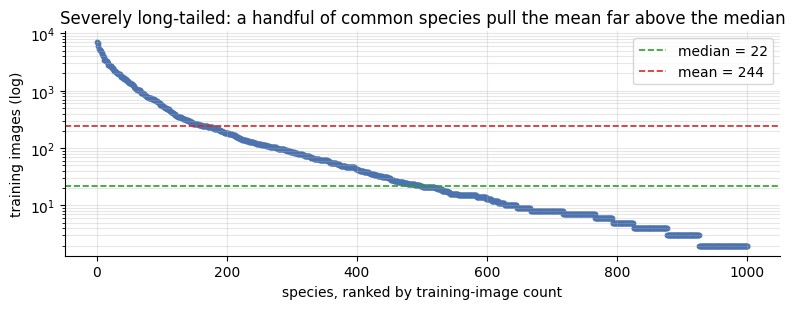

In [2]:
all_rows = load_metadata()
train_rows = rows_for_split(all_rows, "train")
val_rows = rows_for_split(all_rows, "val")
test_rows = rows_for_split(all_rows, "test")
train_counts = images_per_species(train_rows)

print(f"train: {len(train_rows):,}   val: {len(val_rows):,}   test: {len(test_rows):,}   species: {len(train_counts)}")

counts = pd.Series(train_counts).sort_values(ascending=False)
median_count = counts.median()
mean_count = counts.mean()

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.scatter(np.arange(1, len(counts) + 1), counts.values, color="#4c72b0", s=10)
ax.axhline(median_count, color="#2ca02c", linestyle="--", linewidth=1.2,
           label=f"median = {median_count:.0f}")
ax.axhline(mean_count, color="#d62728", linestyle="--", linewidth=1.2,
           label=f"mean = {mean_count:.0f}")
ax.set_yscale("log")
ax.set_xlabel("species, ranked by training-image count")
ax.set_ylabel("training images (log)")
ax.set_title("Severely long-tailed: a handful of common species pull the mean far above the median")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

**Toxicity data - scraped from [ASPCA's cat-toxic-plant pages](https://www.aspca.org/pet-care/animal-poison-control/cats-plant-list)**:
982 pages (`data/raw/aspca/cats_plant_details.json`), a first draft -
never verified, never used as the shipped toxicity table directly
(`aspca_detail.py`). Deduplicated by scientific name into
`data/toxicity.json` (`toxicity_seed.py`) - every entry starts
`"verified": false"` and gets hand-checked one at a time.

In [3]:
toxicity_table = load_table(TOXICITY_TABLE_PATH)
species_rows = load_species_rows()
toxicity_matches = match_against_toxicity_table(species_rows, toxicity_table)

n_verified = sum(1 for e in toxicity_table if e.verified)
n_exact = sum(1 for r in toxicity_matches.values() if r.status == "exact")
n_genus = sum(1 for r in toxicity_matches.values() if r.status == "genus_only")
n_exact_verified = sum(
    1 for r in toxicity_matches.values()
    if r.status == "exact" and r.exact_row.verified
)

aspca_pages = json.loads(ASPCA_DETAILS_JSON_PATH.read_text(encoding="utf-8"))["plants"]

print(f"ASPCA pages scraped:        {len(aspca_pages)}")
print(f"toxicity.json entries:      {len(toxicity_table)}  (deduplicated by scientific name)")
print(f"  of which verified:        {n_verified} / {len(toxicity_table)}")
print()
print(f"PlantNet species w/ EXACT toxicity-table match:  {n_exact} / {len(species_rows)}")
print(f"  of which verified:                             {n_exact_verified} / {n_exact}")
print(f"PlantNet species w/ GENUS-level match only:       {n_genus} / {len(species_rows)}")

ASPCA pages scraped:        982
toxicity.json entries:      571  (deduplicated by scientific name)
  of which verified:        85 / 571

PlantNet species w/ EXACT toxicity-table match:  34 / 1000
  of which verified:                             34 / 34
PlantNet species w/ GENUS-level match only:       240 / 1000


## What makes this hard

1. **Class imbalance.** Median training images/species: 21. Mean: 244.
   Almost half the species (477/1000) have under 20 training images -
   see the chart above and `01_plantnet_class_distribution.ipynb` for
   the full picture.
2. **Toxicity verification is a manual bottleneck, by design.** The
   table above is the live count - it will only grow as entries get
   hand-checked against ASPCA (one at a time, on purpose: no shortcut
   is allowed to produce a `verified: true` entry).
3. **The safety-first rule shapes everything downstream.** A low-data
   species being hard to classify is not just an accuracy problem here
   - it also means the system is *more likely to default to caution*
   (correctly conservative), not more likely to be wrong in a dangerous
   direction. That trade-off (being right vs. being usefully decisive)
   is part of what "good" looks like for this project, not just top-1
   accuracy.

## Roadmap & status

| Phase | What | Status |
|---|---|---|
| 1 | PlantNet-300K baseline (ResNet-18, paper-replica) | ✅ Done - see notebook 03 |
| 2 | Imbalance-aware variants (class-balanced loss / balanced softmax) | ⬜ Not started |
| 3 | Toxicity-aware cost-sensitive training | ⬜ Not started (toxicity-table verification in progress - see above) |
| 4 | Final results, real `check` command | ⬜ Not started |

## Key metrics (the ones we'll report at the end)

Standard ML numbers tell only part of the story for a *toxicity
checker* specifically - see the discussion that led to this list.
`TBD` below is literal: nothing is estimated or guessed ahead of
actually running it.

In [4]:
metrics_path = REPO_ROOT / "outputs" / "plantnet-baseline" / "metrics.json"
breakdown_path = REPO_ROOT / "outputs" / "plantnet-baseline" / "species_breakdown_val.json"

baseline_metrics = json.loads(metrics_path.read_text(encoding="utf-8")) if metrics_path.exists() else None
breakdown = json.loads(breakdown_path.read_text(encoding="utf-8")) if breakdown_path.exists() else None


def bucket_acc(buckets, name, key):
    return f"{buckets[name][key]:.1%}" if buckets and buckets[name][key] is not None else TBD


b = breakdown["buckets"] if breakdown else None

rows = [
    ("val top-1 (species ID)",
     f"{baseline_metrics['val_top1']:.1%}" if baseline_metrics else TBD, TBD, TBD),
    ("val top-5 (species ID)",
     f"{baseline_metrics['val_top5']:.1%}" if baseline_metrics else TBD, TBD, TBD),
    ("test top-1 / top-5 / avg-k (paper's own metric)", TBD, TBD, TBD),
    ("top-1 on species w/ <20 train images", bucket_acc(b, "<20", "top1_accuracy"), TBD, TBD),
    ("top-1 on species w/ 200+ train images", bucket_acc(b, "200+", "top1_accuracy"), TBD, TBD),
    ("top-1 on EXACT toxicity-table matches", TBD, TBD, TBD),
    ("toxicity-table coverage (verified / exact-matched species)",
     f"{n_exact_verified}/{n_exact}", f"{n_exact_verified}/{n_exact}", f"{n_exact_verified}/{n_exact}"),
    ("verdict-tier coverage (% TOXIC / CAUTION / LIKELY_SAFE)", TBD, TBD, TBD),
    ("false-LIKELY_SAFE rate on known-toxic species",
     "0% (structural guarantee - see tests/test_verdict.py, not measured empirically)",
     "same guarantee", "same guarantee"),
]
pd.DataFrame(rows, columns=["metric", "Phase 1 (baseline)", "Phase 2", "Phase 3"]).set_index("metric")

,Phase 1 (baseline),Phase 2,Phase 3
metric,,,
val top-1 (species ID),81.2%,TBD,TBD
val top-5 (species ID),95.6%,TBD,TBD
test top-1 / top-5 / avg-k (paper's own metric),TBD,TBD,TBD
top-1 on species w/ <20 train images,13.1%,TBD,TBD
top-1 on species w/ 200+ train images,86.1%,TBD,TBD
top-1 on EXACT toxicity-table matches,TBD,TBD,TBD
toxicity-table coverage (verified / exact-matched species),34/34,34/34,34/34
verdict-tier coverage (% TOXIC / CAUTION / LIKELY_SAFE),TBD,TBD,TBD
false-LIKELY_SAFE rate on known-toxic species,0% (structural guarantee - see tests/test_verd...,same guarantee,same guarantee


**Reading the table**: the species-ID rows (top-1/top-5/avg-k, and
the data-volume/toxicity-relevance splits) are a genuine model
benchmark - these should improve, phase over phase, if Phase 2/3's
training changes are actually working. The toxicity-table coverage and
false-LIKELY_SAFE rows aren't model metrics at all: coverage only grows
as entries get hand-verified (same number across all three phases
until that work finishes), and the false-safe rate is a property of
`verdict.py`'s code, not of which model is plugged in - it doesn't
improve with a better classifier, it's just true or it isn't.

**Still missing** (explicitly, so it isn't forgotten): test-split
evaluation (`evaluate-plantnet`) hasn't been run yet - everything
above is validation-split, which is what training itself already
looked at to decide when to stop. The verdict-tier coverage row stays
`TBD` for the same reason: it needs a real classifier wired into
`pipeline.py` and real photos (no `check` command exists yet) - it's
an empirical measurement, not something to compute ahead of time.

## The verdict logic, demonstrated

What *can* already be shown, without a real classifier: `verdict.py`
now does genus-fallback matching against `data/toxicity.json`
(`species_match.lookup_toxicity`/`toxicity_category`) instead of a
plain exact-name lookup - a species with no exact entry falls back to
its genus, with a toxic signal from a genus-level placeholder (ASPCA's
own genus-wide claim) treated as confidently as an exact match, a
signal from only a specific relative capped at caution, and neither
ever able to produce `LIKELY_SAFE`.

Not the same thing as the empirical "verdict-tier coverage" row above
(that needs real photos) - this is the **ceiling**: if every one of
PlantNet's 1,000 species were identified with perfect confidence and
nothing else, what would `assess()` say for each one, today, given how
much of the toxicity table is verified so far.

In [5]:
import collections

species_names = [row["full_species"] for row in load_species_rows()]
verdict_counts = collections.Counter()
for name in species_names:
    v = assess([Prediction(name, 1.0)], toxicity_table)
    verdict_counts[v.status] += 1

ceiling_df = pd.DataFrame(
    {"species": [verdict_counts[s] for s in Status]},
    index=[s.value for s in Status],
)
ceiling_df["share"] = (ceiling_df["species"] / len(species_names)).map("{:.1%}".format)
ceiling_df

,species,share
toxic,39,3.9%
caution,933,93.3%
likely_safe,28,2.8%


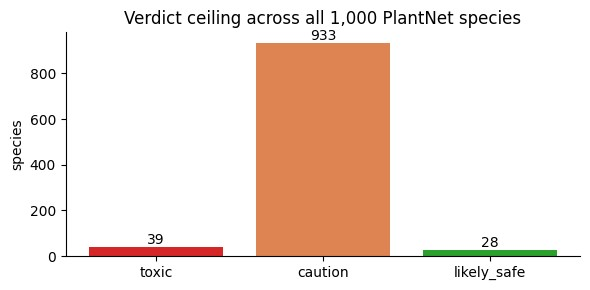

Confirmed: every LIKELY_SAFE verdict above has an exact, verified non-toxic entry.


In [6]:
fig, ax = plt.subplots(figsize=(6, 3))
colors = {"toxic": "#d62728", "caution": "#dd8452", "likely_safe": "#2ca02c"}
ax.bar(ceiling_df.index, ceiling_df["species"], color=[colors[s] for s in ceiling_df.index])
ax.set_ylabel("species")
ax.set_title("Verdict ceiling across all 1,000 PlantNet species")
for i, status in enumerate(ceiling_df.index):
    ax.text(i, ceiling_df["species"][status], str(ceiling_df["species"][status]), ha="center", va="bottom")
plt.tight_layout()
plt.show()

# Structural guarantee, checked here rather than just asserted: every
# LIKELY_SAFE verdict above really does rest on an exact, verified
# non-toxic entry - never a genus-level inference.
for name in species_names:
    v = assess([Prediction(name, 1.0)], toxicity_table)
    if v.status is Status.LIKELY_SAFE:
        assert v.entry is not None and v.entry.verified and v.entry.toxic_to_cats == "no"
print("Confirmed: every LIKELY_SAFE verdict above has an exact, verified non-toxic entry.")

**`CAUTION` isn't one thing.** 933 species land there, but for
different reasons - a species whose genus has a known-toxic relative
is a very different kind of "we're not sure" than a species the
toxicity table has nothing at all to say about. Splitting it by the
underlying match category (the same ``toxicity_category`` used above):

In [7]:
toxicity_index = build_toxicity_index(toxicity_table)
caution_reasons = collections.Counter()
for name in species_names:
    v = assess([Prediction(name, 1.0)], toxicity_table)
    if v.status is Status.CAUTION:
        caution_reasons[toxicity_category(lookup_toxicity(name, toxicity_index))] += 1

CAUTION_LABELS = {
    "genus - toxic (inferred)": "toxic relative in the genus",
    "genus - non-toxic (direct)": "genus page itself says non-toxic",
    "genus - non-toxic (inferred)": "non-toxic relative in the genus",
    "no match": "nothing in the table at all",
}
caution_df = pd.DataFrame(
    {"species": [caution_reasons.get(cat, 0) for cat in CAUTION_LABELS]},
    index=[CAUTION_LABELS[cat] for cat in CAUTION_LABELS],
)
caution_df["share of all CAUTION"] = (caution_df["species"] / caution_df["species"].sum()).map("{:.1%}".format)
caution_df

,species,share of all CAUTION
toxic relative in the genus,72,7.7%
genus page itself says non-toxic,23,2.5%
non-toxic relative in the genus,112,12.0%
nothing in the table at all,726,77.8%


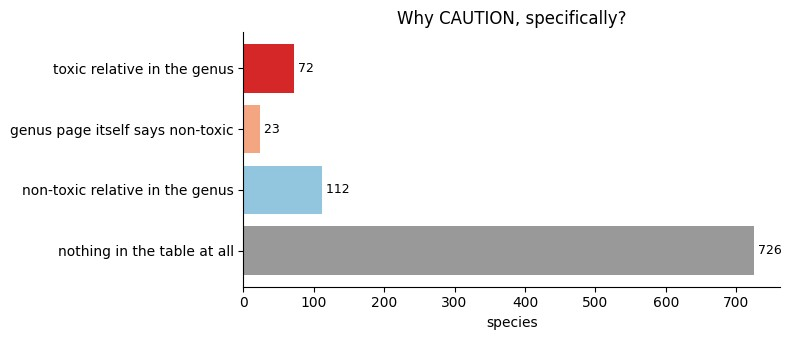

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
colors = ["#d62728", "#f4a582", "#92c5de", "#999999"]
ax.barh(caution_df.index, caution_df["species"], color=colors)
ax.invert_yaxis()
ax.set_xlabel("species")
ax.set_title("Why CAUTION, specifically?")
for i, n in enumerate(caution_df["species"]):
    ax.text(n, i, f" {n}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

Only 72 of the 933 are "a specific relative is toxic" - the
`Tradescantia fluminensis` case below. The other 861 are species the
table either says nothing about at all (726), or where a relative
points *towards* safety but can't structurally be trusted to confirm
it (135 - the genus-level non-toxic signal that, by design, can never
promote to `LIKELY_SAFE`). That second group is arguably the most
promising place for future verification effort: unlike "no match", it
already has *some* real signal.

A real example of each path the matching logic can take, reason
text and all - this is exactly what a real `check` command would show
a user. Four genuinely different PlantNet species, chosen to exercise
each case (not just the first one found):

- an **exact** match (`Hypericum perforatum` is itself in the table)
- a **genus - direct** match (`Pelargonium capitatum` isn't in the
  table, but ASPCA's own genus-wide `"Pelargonium species"` page is)
- a **genus - inferred** match (`Tradescantia fluminensis` isn't in
  the table and there's no genus placeholder either - only a
  *specific*, different relative, `tradescantia multiflora`, happens
  to be toxic)
- an **exact, verified non-toxic** match (`Nephrolepis exaltata` -
  the only kind of match that can ever reach `LIKELY_SAFE`)

In [9]:
demo_species = [
    "Hypericum perforatum L.",
    "Pelargonium capitatum (L.) L'Hér.",
    "Tradescantia fluminensis Vell.",
    "Nephrolepis exaltata (L.) Schott",
]
for name in demo_species:
    v = assess([Prediction(name, 1.0)], toxicity_table)
    print(f"{v.status.value:>12}: {name}")
    for reason in v.reasons:
        print(f"             {reason}")
    print()

       toxic: Hypericum perforatum L.
             Best match 'Hypericum perforatum L.' is toxic to cats.

       toxic: Pelargonium capitatum (L.) L'Hér.
             Best match 'Pelargonium capitatum (L.) L'Hér.' is in a genus ASPCA lists as toxic to cats.

     caution: Tradescantia fluminensis Vell.
             'Tradescantia fluminensis Vell.' is not itself in the toxicity table, but a relative, 'Tradescantia flumeninsis', is toxic to cats; treat as toxic.

 likely_safe: Nephrolepis exaltata (L.) Schott
             'Nephrolepis exaltata (L.) Schott' is verified non-toxic to cats and the match is confident. Still check with a vet if a cat ate any.



## Next up

- Keep working through the toxicity table (34 exact PlantNet matches
  first, then the 51 genus-level ones) - the live counts above update
  automatically as that happens.
- Scope Phase 2 (imbalance-aware training) once there's enough
  verified toxicity data to also start Phase 3 design in parallel.
- Re-run this notebook whenever something changes - that's the point.